In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- edit these two to match your CSV ---
DATE_COL  = "date"
LEVEL_COL = "water_level_mean"
# ----------------------------------------

DATA_PATH  = "../data/processed/kaub_water_weather_daily.csv"
HORIZON    = 7       # forecast 7 days ahead
TEST_YEARS = 3       # hold out the most recent 3 years

pd.set_option("display.width", 120)


date                 datetime64[us]
water_level_mean            float64
water_level_min             float64
water_level_max             float64
hours_available               int64
temperature_mean            float64
humidity_mean               float64
precipitation_sum           float64
rain_sum                    float64
snowfall_sum                float64
pressure_mean               float64
wind_speed_mean             float64
et0_sum                     float64
hours_expected                int64
dtype: object
        date  water_level_mean  water_level_min  water_level_max  hours_available  temperature_mean  humidity_mean  \
0 2000-01-01        438.989130            420.0            459.0               23          3.430435      97.565217   
1 2000-01-02        401.260417            384.0            420.0               24          3.866667      96.208333   
2 2000-01-03        367.989583            359.0            384.0               24          2.354167      94.333333   

   precip

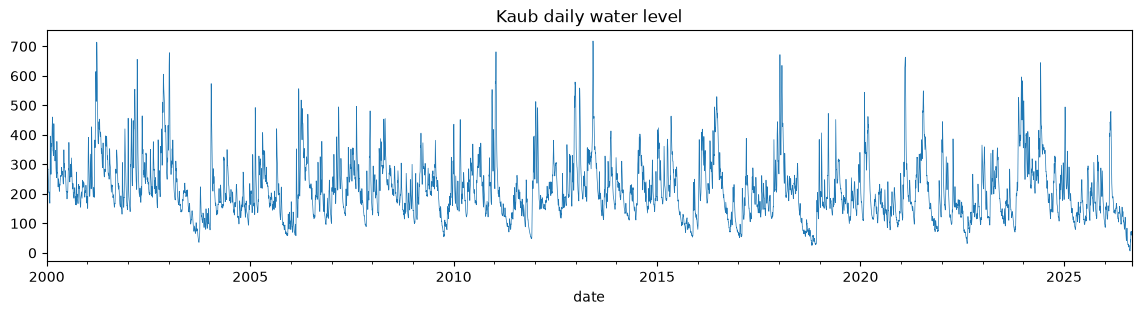

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(df.dtypes)
print(df.head(3))# sanity-check your two constants

s = (df[[DATE_COL, LEVEL_COL]]
     .dropna(subset=[DATE_COL])
     .sort_values(DATE_COL)
     .drop_duplicates(subset=[DATE_COL], keep="last")
     .set_index(DATE_COL)[LEVEL_COL]
     .asfreq("D"))                            # explicit NaN for absent days

print(f"{s.index.min().date()} → {s.index.max().date()}  ({len(s)} days)")
print("missing days:", int(s.isna().sum()))
s.plot(figsize=(14, 3), lw=0.5, title="Kaub daily water level")
plt.show()


In [4]:
H    = HORIZON
LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

data = pd.DataFrame(index=s.index)
for L in LAGS:
    data[f"lag_{L}"] = s.shift(L)            # all ≤ day t
data["target"] = s.shift(-H)                 # day t+7

FEATURES = [f"lag_{L}" for L in LAGS]
data.head(35)


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14,lag_21,lag_28,target
date,,,,,,,,,,,,
2000-01-01,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,304.572917
2000-01-02,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,293.968750
2000-01-03,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,285.385417
2000-01-04,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,282.166667
2000-01-05,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,NaN,284.072917
2000-01-06,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,NaN,272.229167
2000-01-07,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,NaN,259.875000
2000-01-08,304.572917,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,438.989130,NaN,NaN,NaN,250.281250
2000-01-09,293.968750,304.572917,303.635417,311.135417,327.968750,346.093750,367.989583,401.260417,NaN,NaN,NaN,237.739583


In [5]:
i = 400
row = data.iloc[i]
assert row["lag_0"] == s.iloc[i]                 # feature is today
assert row["target"] == s.iloc[i + H]            # target is today + 7
print(f"on {data.index[i].date()}: today={row['lag_0']}, target(+7d)={row['target']}")


on 2001-02-04: today=230.09375, target(+7d)=308.15625


In [6]:
split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)

train = data.loc[: split_date - pd.Timedelta(days=H)].dropna()
test  = data.loc[split_date + pd.Timedelta(days=1):].dropna()

X_train, y_train = train[FEATURES], train["target"]
X_test,  y_test  = test[FEATURES],  test["target"]

print(f"train: {train.index.min().date()} → {train.index.max().date()}  n={len(train)}")
print(f"test : {test.index.min().date()} → {test.index.max().date()}  n={len(test)}")
assert train.index.max() + pd.Timedelta(days=H) < test.index.min(), "embargo violated"


train: 2000-01-29 → 2023-08-25  n=8610
test : 2023-09-02 → 2026-08-25  n=1089


In [7]:
pred_persist = X_test["lag_0"].rename("persistence")


In [8]:
from sklearn.linear_model import LinearRegression

ar = LinearRegression()
ar.fit(X_train, y_train)

pred_ar = pd.Series(ar.predict(X_test), index=X_test.index, name="linear_ar")

print(pd.Series(ar.coef_, index=FEATURES).round(3))
print("intercept:", round(ar.intercept_, 2))


lag_0     1.807
lag_1    -2.006
lag_2     1.105
lag_3    -0.433
lag_4     0.130
lag_5     0.060
lag_6    -0.192
lag_7     0.203
lag_14    0.096
lag_21    0.007
lag_28    0.006
dtype: float64
intercept: 46.59


In [9]:
def evaluate(y_true, y_pred, name):
    err = y_true - y_pred
    return pd.Series({
        "MAE":  err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias": err.mean(),
    }, name=name)

results = pd.concat([
    evaluate(y_test, pred_persist, "persistence"),
    evaluate(y_test, pred_ar,      "linear_ar"),
], axis=1).T

rmse_p, rmse_a = results.loc["persistence", "RMSE"], results.loc["linear_ar", "RMSE"]
results["skill_vs_persistence"] = [0.0, 1 - (rmse_a ** 2) / (rmse_p ** 2)]

print(f"Horizon: {H} days   |   test n = {len(y_test)}")
print(results.round(3))


Horizon: 7 days   |   test n = 1089
                MAE    RMSE   bias  skill_vs_persistence
persistence  50.834  72.463 -0.943                 0.000
linear_ar    49.032  66.857 -1.708                 0.149


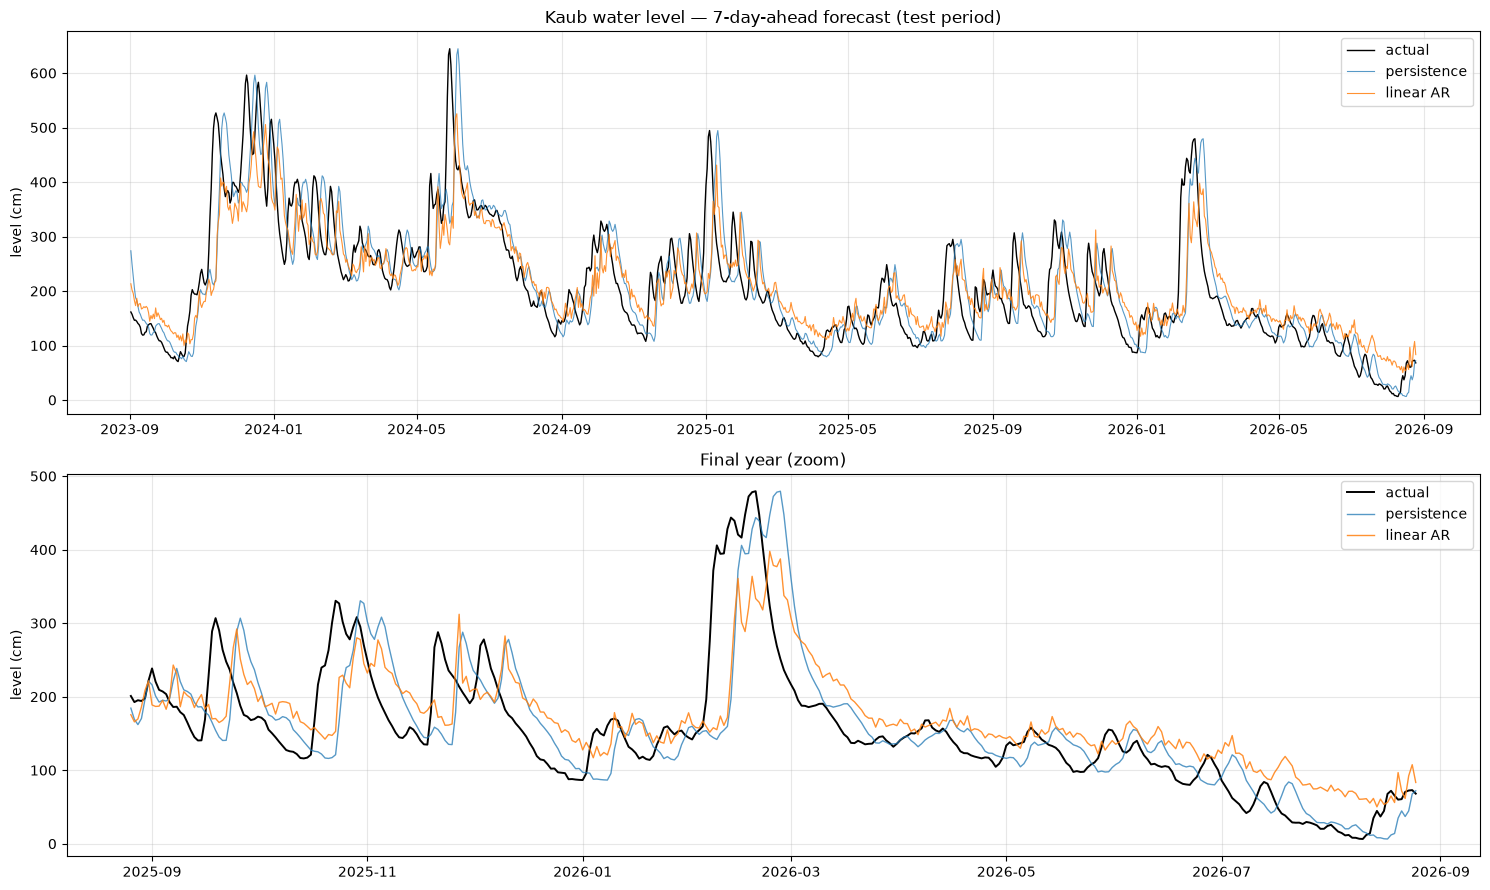

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

ax = axes[0]
ax.plot(y_test.index, y_test,      lw=1.0, color="black", label="actual")
ax.plot(pred_persist.index, pred_persist, lw=0.8, alpha=.75, label="persistence")
ax.plot(pred_ar.index, pred_ar,          lw=0.8, alpha=.85, label="linear AR")
ax.set_title(f"Kaub water level — {H}-day-ahead forecast (test period)")
ax.set_ylabel("level (cm)"); ax.legend(); ax.grid(alpha=.3)

zoom = y_test.index[-365:]
ax = axes[1]
ax.plot(zoom, y_test.loc[zoom],      lw=1.4, color="black", label="actual")
ax.plot(zoom, pred_persist.loc[zoom], lw=1.0, alpha=.75, label="persistence")
ax.plot(zoom, pred_ar.loc[zoom],      lw=1.0, alpha=.85, label="linear AR")
ax.set_title("Final year (zoom)"); ax.set_ylabel("level (cm)")
ax.legend(); ax.grid(alpha=.3)

plt.tight_layout(); plt.show()


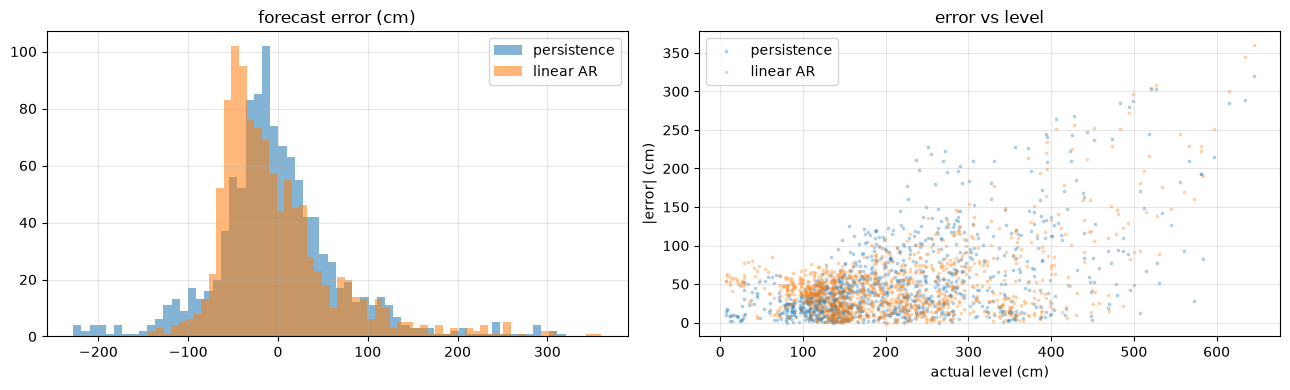

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p, n in [(pred_persist, "persistence"), (pred_ar, "linear AR")]:
    ax[0].hist(y_test - p, bins=60, alpha=.55, label=n)
    ax[1].scatter(y_test, (y_test - p).abs(), s=3, alpha=.25, label=n)
ax[0].set_title("forecast error (cm)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("actual level (cm)"); ax[1].set_ylabel("|error| (cm)")
ax[1].set_title("error vs level"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
